In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_curve
)

RANDOM_STATE = 42
N_SPLITS = 5
TARGET_COLUMN = "Machine failure"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
cwd = Path.cwd()

PROJECT_ROOT = next(
    (
        path
        for path in [cwd, *cwd.parents]
        if (path / "data" / "raw" / "ai4i2020.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/ai4i2020.csv. "
        "Check the notebook's working directory."
    )

df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv")

NUMERICAL_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

CATEGORICAL_FEATURES = ["Type"]
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training failures:", int(y_train.sum()))
print("Test failures:", int(y_test.sum()))

Training shape: (8000, 6)
Test shape: (2000, 6)
Training failures: 271
Test failures: 68


In [3]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERICAL_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
])

print("Preprocessing pipeline configured.")

Preprocessing pipeline configured.


In [4]:
models = {
    "Hist_Gradient_Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.1,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random_Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    print(f"{name}: {model.named_steps['classifier'].__class__.__name__}")

Hist_Gradient_Boosting: HistGradientBoostingClassifier
Random_Forest: RandomForestClassifier


In [5]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

oof_probabilities = {}
oof_results = []

for name, model in models.items():
    print(f"Generating out-of-fold predictions: {name}")

    probabilities = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    oof_probabilities[name] = probabilities

    oof_results.append({
        "model": name,
        "average_precision": average_precision_score(y_train, probabilities),
        "roc_auc": roc_auc_score(y_train, probabilities)
    })

oof_comparison = pd.DataFrame(oof_results).sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

oof_comparison.round(4)

Generating out-of-fold predictions: Hist_Gradient_Boosting
Generating out-of-fold predictions: Random_Forest


,model,average_precision,roc_auc
0,Hist_Gradient_Boosting,0.7778,0.9705
1,Random_Forest,0.7215,0.9686


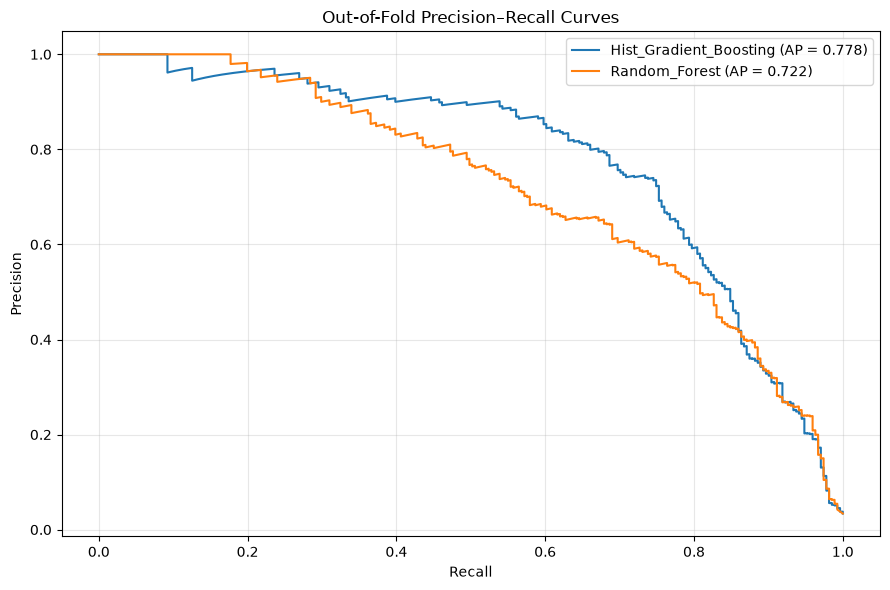

In [6]:
plt.figure(figsize=(9, 6))

for name, probabilities in oof_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_train, probabilities)
    ap = average_precision_score(y_train, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-Fold Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)

threshold_results = []

for name, probabilities in oof_probabilities.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_train,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "model": name,
            "threshold": threshold,
            "precision": precision_score(
                y_train, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_train, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_train, predictions, zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_train, predictions
            ),
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "false_alarms_per_1000": fp / len(y_train) * 1000
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.head()

,model,threshold,precision,recall,f1,balanced_accuracy,TP,FP,TN,FN,false_alarms_per_1000
0,Hist_Gradient_Boosting,0.0500,0.2724,0.9188,0.4203,0.9164,249,665,7064,22,83.1250
1,Hist_Gradient_Boosting,0.1000,0.3311,0.8967,0.4836,0.9166,243,491,7238,28,61.3750
2,Hist_Gradient_Boosting,0.1500,0.3686,0.8745,0.5186,0.9110,237,406,7323,34,50.7500
3,Hist_Gradient_Boosting,0.2000,0.4084,0.8635,0.5545,0.9098,234,339,7390,37,42.3750
4,Hist_Gradient_Boosting,0.2500,0.4455,0.8598,0.5869,0.9111,233,290,7439,38,36.2500


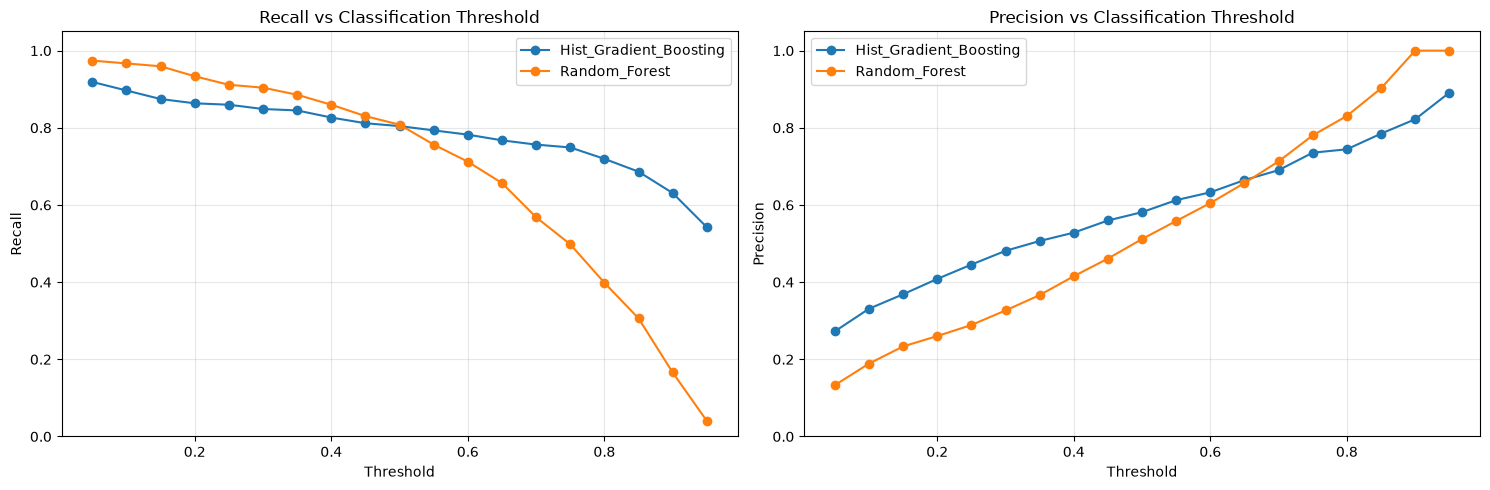

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name in models:
    subset = threshold_df[threshold_df["model"] == name]

    axes[0].plot(
        subset["threshold"],
        subset["recall"],
        marker="o",
        label=name
    )

    axes[1].plot(
        subset["threshold"],
        subset["precision"],
        marker="o",
        label=name
    )

axes[0].set_title("Recall vs Classification Threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Recall")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Precision vs Classification Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
PLOTS_DIR = PROJECT_ROOT / "artifacts" / "plots"
REPORTS_DIR = PROJECT_ROOT / "artifacts" / "reports"

for folder in [METRICS_DIR, PLOTS_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

oof_comparison.to_csv(
    METRICS_DIR / "oof_model_comparison.csv",
    index=False
)

threshold_df.to_csv(
    METRICS_DIR / "threshold_analysis.csv",
    index=False
)

print("Saved:")
print(METRICS_DIR / "oof_model_comparison.csv")
print(METRICS_DIR / "threshold_analysis.csv")

Saved:
d:\robotic-predictive-maintenance\artifacts\metrics\oof_model_comparison.csv
d:\robotic-predictive-maintenance\artifacts\metrics\threshold_analysis.csv


In [10]:
MIN_RECALL = 0.85

eligible = threshold_df[
    threshold_df["recall"] >= MIN_RECALL
].copy()

best_thresholds = (
    eligible
    .sort_values(
        ["model", "precision", "threshold"],
        ascending=[True, False, False]
    )
    .groupby("model", as_index=False)
    .first()
)

display(
    best_thresholds[
        [
            "model",
            "threshold",
            "precision",
            "recall",
            "f1",
            "TP",
            "FP",
            "FN",
            "false_alarms_per_1000"
        ]
    ].round(4)
)

,model,threshold,precision,recall,f1,TP,FP,FN,false_alarms_per_1000
0,Hist_Gradient_Boosting,0.2500,0.4455,0.8598,0.5869,233,290,38,36.2500
1,Random_Forest,0.4000,0.4153,0.8598,0.5601,233,328,38,41.0000
